# Week 6-7: Artificial Neural Network Implementation
**Dataset:** Kaggle - Android Permission Dataset  
**Framework:** scikit-learn MLPClassifier (Multilayer Perceptron ANN)  
**Goal:** Train and compare 4 ANN architectures x 2 dataset versions = 8 experiments for Android malware detection.

---
## Step 0: Setup - Import Libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)
import sklearn

SEED = 42
np.random.seed(SEED)

print('scikit-learn version :', sklearn.__version__)
print('numpy version        :', np.__version__)
print('pandas version       :', pd.__version__)
print('All libraries loaded successfully.')

scikit-learn version : 1.5.0
numpy version        : 2.2.6
pandas version       : 2.2.2
All libraries loaded successfully.


---
## Step 1: Load Data

In [2]:
df_raw = pd.read_csv('Android_Permission.csv')

print('Dataset shape :', df_raw.shape, '(rows x columns)')
print('Total columns :', len(df_raw.columns))

# Permission columns always start with one of these prefixes
PERM_PREFIXES = (
    'Default', 'Development tools', 'Hardware controls',
    'Network communication', 'Phone calls',
    'Services that cost you money', 'Storage', 'System tools',
    'Your accounts', 'Your location', 'Your messages',
    'Your personal information'
)

perm_cols = [c for c in df_raw.columns if c.startswith(PERM_PREFIXES)]
gen_cols  = [c for c in df_raw.columns if c not in perm_cols]

N = 5  # columns to preview per group

print('\n' + '-'*60)
print('  GENERAL INFO COLUMNS (%d total, showing %d)' % (len(gen_cols), N))
print('-'*60)
for i, col in enumerate(gen_cols[:N], 1):
    print('  %2d. %s' % (i, col))
if len(gen_cols) > N:
    print('  ... and %d more' % (len(gen_cols) - N))

print('\n' + '-'*60)
print('  PERMISSION COLUMNS (%d total, showing %d)' % (len(perm_cols), N))
print('-'*60)
for i, col in enumerate(perm_cols[:N], 1):
    print('  %2d. %s' % (i, col))
if len(perm_cols) > N:
    print('  ... and %d more' % (len(perm_cols) - N))


Dataset shape : (29999, 184) (rows x columns)
Total columns : 184

------------------------------------------------------------
  GENERAL INFO COLUMNS (11 total, showing 5)
------------------------------------------------------------
   1. App
   2. Package
   3. Category
   4. Description
   5. Rating
  ... and 6 more

------------------------------------------------------------
  PERMISSION COLUMNS (173 total, showing 5)
------------------------------------------------------------
   1. Default : Access DRM content. (S)
   2. Default : Access Email provider data (S)
   3. Default : Access all system downloads (S)
   4. Default : Access download manager. (S)
   5. Default : Advanced download manager functions. (S)
  ... and 168 more


In [3]:
df_raw.head(3)

,App,Package,Category,Description,Rating,Number of ratings,Price,Related apps,Dangerous permissions count,Safe permissions count,...,Your personal information : read calendar events (D),Your personal information : read contact data (D),Your personal information : read sensitive log data (D),Your personal information : read user defined dictionary (D),Your personal information : retrieve system internal state (S),Your personal information : set alarm in alarm clock (S),Your personal information : write Browser's history and bookmarks (D),Your personal information : write contact data (D),Your personal information : write to user defined dictionary (S),Class
0,Canada Post Corporation,com.canadapost.android,Business,Canada Post Mobile App gives you access to som...,3.1,77,0.0,"{com.adaffix.pub.ca.android, com.kevinquan.gas...",7.0,1,...,0,1,0,0,0,0,0,1,0,0
1,Word Farm,com.realcasualgames.words,Brain & Puzzle,Speed and strategy combine in this exciting wo...,4.3,199,0.0,"{air.com.zubawing.FastWordLite, com.joybits.do...",3.0,2,...,0,0,0,0,0,0,0,0,0,0
2,Fortunes of War FREE,fortunesofwar.free,Cards & Casino,"Fortunes of War is a fast-paced, easy to learn...",4.1,243,0.0,"{com.kevinquan.condado, hu.monsta.pazaak, net....",1.0,1,...,0,0,0,0,0,0,0,0,0,0


In [4]:
df_raw.info(verbose=False, show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Columns: 184 entries, App to Class
dtypes: float64(3), int64(176), object(5)
memory usage: 42.1+ MB


---
## Step 2: Data Cleaning

In [5]:
# 2a. Remove non-numeric / irrelevant columns
NON_NUMERIC_COLS = ['App', 'Category', 'Description', 'Package', 'Related apps']
cols_to_drop = [c for c in NON_NUMERIC_COLS if c in df_raw.columns]
print('Non-numeric columns dropped :', cols_to_drop)

df = df_raw.drop(columns=cols_to_drop, errors='ignore').copy()

# 2b. Verify target column
assert 'Class' in df.columns, "Target column 'Class' not found!"

# 2c. Separate features and target
y_full = df['Class'].copy()
X_full = df.drop(columns=['Class']).copy()

# 2d. Keep only numeric columns
X_full = X_full.select_dtypes(include=[np.number])
print('Numeric feature columns     :', X_full.shape[1])

# 2e. Drop constant / all-zero columns
zero_cols  = X_full.columns[X_full.sum() == 0].tolist()
const_cols = X_full.columns[X_full.nunique() <= 1].tolist()
drop_cols  = list(set(zero_cols + const_cols))
X_full.drop(columns=drop_cols, inplace=True)

# 2f. Handle missing values (median imputation)
X_full.fillna(X_full.median(), inplace=True)

# 2g. Remove duplicate rows
combined  = pd.concat([X_full, y_full], axis=1)
dup_count = combined.duplicated().sum()
combined.drop_duplicates(inplace=True)
X_full    = combined.drop(columns=['Class'])
y_full    = combined['Class']
print('Duplicate rows removed      :', f'{dup_count:,}')

# 2h. Confirm binary target (0=Benign, 1=Malware)
assert sorted(y_full.unique()) == [0, 1], "Target is not binary 0/1!"

print('Final cleaned dataset       :', f'{X_full.shape[0]:,} rows x {X_full.shape[1]} features')

# Output: Remaining feature columns (showing few initial)
SHOW_N = 5
print('\n' + '-' * 60)
print(f'  REMAINING FEATURE COLUMNS ({len(X_full.columns)} total, showing {SHOW_N})')
print('-' * 60)
for i, col in enumerate(X_full.columns[:SHOW_N], 1):
    print(f'   {i}. {col}')
print(f'  ... and {len(X_full.columns) - SHOW_N} more')


Non-numeric columns dropped : ['App', 'Category', 'Description', 'Package', 'Related apps']
Numeric feature columns     : 178
Duplicate rows removed      : 7,420
Final cleaned dataset       : 22,579 rows x 156 features

------------------------------------------------------------
  REMAINING FEATURE COLUMNS (156 total, showing 5)
------------------------------------------------------------
   1. Rating
   2. Number of ratings
   3. Price
   4. Dangerous permissions count
   5. Safe permissions count
  ... and 151 more


In [6]:
# Class distribution summary
counts = y_full.value_counts().sort_index()
total = len(y_full)

print('-' * 60)
print("  CLASS DISTRIBUTION (TARGET: 'Class')")
print('-' * 60)
print(f"  Class 0 (Benign)  : {counts[0]:>7,}  ({(counts[0]/total)*100:6.2f}%)")
print(f"  Class 1 (Malware) : {counts[1]:>7,}  ({(counts[1]/total)*100:6.2f}%)")
print(f"  Total             : {total:>7,}  (100.00%)")
print('-' * 60)


------------------------------------------------------------
  CLASS DISTRIBUTION (TARGET: 'Class')
------------------------------------------------------------
  Class 0 (Benign)  :   8,777  ( 38.87%)
  Class 1 (Malware) :  13,802  ( 61.13%)
  Total             :  22,579  (100.00%)
------------------------------------------------------------


---
## Step 3: Train / Test Split (Stratified 80/20)

In [7]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_full, y_full,
    test_size=0.2,
    random_state=SEED,
    stratify=y_full
)

INPUT_DIM = X_train_raw.shape[1]

# Distribution counts
tr_counts = y_train.value_counts().sort_index()
te_counts = y_test.value_counts().sort_index()
n_tr, n_te = len(y_train), len(y_test)
total_samples = n_tr + n_te

print('-' * 70)
print('  TRAIN / TEST SPLIT SUMMARY (80% Train / 20% Test)')
print('-' * 70)
print(f'  Total Cleaned Samples : {total_samples:,}')
print(f'  Input Features (ANN)  : {INPUT_DIM}\n')
print(f"  {'Subset':<10} {'Benign (0)':<18} {'Malware (1)':<18} {'Total'}")
print('  ' + '-' * 66)
print(f"  {'Train':<10} {tr_counts[0]:>5,d} ({(tr_counts[0]/n_tr)*100:5.2f}%)    {tr_counts[1]:>6,d} ({(tr_counts[1]/n_tr)*100:5.2f}%)   {n_tr:>6,d} ({(n_tr/total_samples)*100:4.1f}%)")
print(f"  {'Test':<10} {te_counts[0]:>5,d} ({(te_counts[0]/n_te)*100:5.2f}%)    {te_counts[1]:>6,d} ({(te_counts[1]/n_te)*100:5.2f}%)   {n_te:>6,d} ({(n_te/total_samples)*100:4.1f}%)")
print('-' * 70)


----------------------------------------------------------------------
  TRAIN / TEST SPLIT SUMMARY (80% Train / 20% Test)
----------------------------------------------------------------------
  Total Cleaned Samples : 22,579
  Input Features (ANN)  : 156

  Subset     Benign (0)         Malware (1)        Total
  ------------------------------------------------------------------
  Train      7,022 (38.88%)    11,041 (61.12%)   18,063 (80.0%)
  Test       1,755 (38.86%)     2,761 (61.14%)    4,516 (20.0%)
----------------------------------------------------------------------


---
## Step 4: Dataset Preparation - Raw and Normalized

In [8]:
# MinMaxScaler: fit on TRAIN only, then transform both sets (no data leakage)
scaler       = MinMaxScaler()
X_train_norm = scaler.fit_transform(X_train_raw)
X_test_norm  = scaler.transform(X_test_raw)

X_train_raw_np = X_train_raw.values
X_test_raw_np  = X_test_raw.values
y_train_np     = y_train.values
y_test_np      = y_test.values

print('Raw data      - Train:', X_train_raw_np.shape, ', Test:', X_test_raw_np.shape)
print('Normalized    - Train:', X_train_norm.shape, ',  Test:', X_test_norm.shape)
print('Input dimension (# features):', INPUT_DIM)

Raw data      - Train: (18063, 156) , Test: (4516, 156)
Normalized    - Train: (18063, 156) ,  Test: (4516, 156)
Input dimension (# features): 156


---
## Step 4: ANN Model Definitions

Using `sklearn.neural_network.MLPClassifier` - a proper Multilayer Perceptron ANN.

| Model | Hidden Layer Sizes | Total Layers |
|-------|-------------------|-------------|
| Model 1 | 128, 64, 32, 16, 8 | 6 (5 hidden + 1 output) |
| Model 2 | 64, 32, 16, 8      | 5 (4 hidden + 1 output) |
| Model 3 | 32, 16, 8          | 4 (3 hidden + 1 output) |
| Model 4 | 16, 8              | 3 (2 hidden + 1 output) |

> In MLPClassifier, the output layer (1 unit with logistic/sigmoid activation) is added automatically for binary classification.

In [9]:
MODEL_CONFIGS = {
    'Model 1 (6L: 128-64-32-16-8-1)': (128, 64, 32, 16, 8),
    'Model 2 (5L: 64-32-16-8-1)'    : (64, 32, 16, 8),
    'Model 3 (4L: 32-16-8-1)'       : (32, 16, 8),
    'Model 4 (3L: 16-8-1)'          : (16, 8),
}

def build_mlp(hidden_layer_sizes):
    return MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation='relu',
        solver='adam',
        alpha=1e-4,
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=50,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=10,
        random_state=SEED,
        verbose=False
    )

print('ANN Architectures (hidden_layer_sizes + implicit output layer):')
print('-' * 65)
for name, sizes in MODEL_CONFIGS.items():
    full_arch = list(sizes) + [1]
    print('  ' + name)
    print('    Hidden layers :', sizes)
    print('    Full arch     :', full_arch, '(output=1 neuron, sigmoid)')
    print()

ANN Architectures (hidden_layer_sizes + implicit output layer):
-----------------------------------------------------------------
  Model 1 (6L: 128-64-32-16-8-1)
    Hidden layers : (128, 64, 32, 16, 8)
    Full arch     : [128, 64, 32, 16, 8, 1] (output=1 neuron, sigmoid)

  Model 2 (5L: 64-32-16-8-1)
    Hidden layers : (64, 32, 16, 8)
    Full arch     : [64, 32, 16, 8, 1] (output=1 neuron, sigmoid)

  Model 3 (4L: 32-16-8-1)
    Hidden layers : (32, 16, 8)
    Full arch     : [32, 16, 8, 1] (output=1 neuron, sigmoid)

  Model 4 (3L: 16-8-1)
    Hidden layers : (16, 8)
    Full arch     : [16, 8, 1] (output=1 neuron, sigmoid)



---
## Step 4: Training - 8 Experiments (4 Models x 2 Dataset Versions)

In [10]:
DATASETS = {
    'Raw'       : (X_train_raw_np, X_test_raw_np),
    'Normalized': (X_train_norm,   X_test_norm),
}

results        = []
trained_models = {}

total_exps = len(MODEL_CONFIGS) * len(DATASETS)
print(f'Total experiments: {total_exps}')
print('Starting training...\n')

exp_num = 0
for ds_name, (X_tr, X_te) in DATASETS.items():
    for model_name, hidden_sizes in MODEL_CONFIGS.items():
        exp_num += 1
        exp_key = ds_name + ' | ' + model_name

        model = build_mlp(hidden_sizes)
        model.fit(X_tr, y_train_np)

        epochs_run = model.n_iter_
        trained_models[exp_key] = model

        y_pred_train = model.predict(X_tr)
        y_pred       = model.predict(X_te)

        train_metrics = {
            'Train Accuracy' : accuracy_score(y_train_np, y_pred_train),
            'Train Precision': precision_score(y_train_np, y_pred_train, zero_division=0),
            'Train Recall'   : recall_score(y_train_np, y_pred_train, zero_division=0),
            'Train F1'       : f1_score(y_train_np, y_pred_train, zero_division=0),
        }
        test_metrics = {
            'Test Accuracy' : accuracy_score(y_test_np, y_pred),
            'Test Precision': precision_score(y_test_np, y_pred, zero_division=0),
            'Test Recall'   : recall_score(y_test_np, y_pred, zero_division=0),
            'Test F1'       : f1_score(y_test_np, y_pred, zero_division=0),
        }

        record = {
            'Dataset'   : ds_name,
            'Model'     : model_name,
            'Exp Key'   : exp_key,
            'Epochs Run': epochs_run,
            '_y_pred'   : y_pred,
        }
        record.update(train_metrics)
        record.update(test_metrics)
        results.append(record)

        short_model = model_name.split(':')[0] + ')'
        print(f'[{exp_num}/{total_exps}] {ds_name:<10} | {short_model:<15} -> Iter: {epochs_run:>2} | Train Acc: {train_metrics["Train Accuracy"]:.4f} | Test Acc: {test_metrics["Test Accuracy"]:.4f} | Test F1: {test_metrics["Test F1"]:.4f}')

print('\nAll 8 experiments completed!')


Total experiments: 8
Starting training...

[1/8] Raw        | Model 1 (6L)    -> Iter: 32 | Train Acc: 0.6785 | Test Acc: 0.6767 | Test F1: 0.7020
[2/8] Raw        | Model 2 (5L)    -> Iter: 32 | Train Acc: 0.6730 | Test Acc: 0.6718 | Test F1: 0.6916
[3/8] Raw        | Model 3 (4L)    -> Iter: 35 | Train Acc: 0.6829 | Test Acc: 0.6807 | Test F1: 0.7097
[4/8] Raw        | Model 4 (3L)    -> Iter: 50 | Train Acc: 0.6961 | Test Acc: 0.6949 | Test F1: 0.7308
[5/8] Normalized | Model 1 (6L)    -> Iter: 39 | Train Acc: 0.7285 | Test Acc: 0.6506 | Test F1: 0.7121
[6/8] Normalized | Model 2 (5L)    -> Iter: 29 | Train Acc: 0.6914 | Test Acc: 0.6468 | Test F1: 0.7315
[7/8] Normalized | Model 3 (4L)    -> Iter: 17 | Train Acc: 0.6370 | Test Acc: 0.6377 | Test F1: 0.7426
[8/8] Normalized | Model 4 (3L)    -> Iter: 27 | Train Acc: 0.6400 | Test Acc: 0.6399 | Test F1: 0.7417

All 8 experiments completed!


---
## Step 5: Evaluation and Comparison

In [11]:
# Full summary table
display_cols = [
    'Dataset', 'Model', 'Epochs Run',
    'Train Accuracy', 'Train Precision', 'Train Recall', 'Train F1',
    'Test Accuracy',  'Test Precision',  'Test Recall',  'Test F1',
]
results_df  = pd.DataFrame(results)[display_cols].copy()
metric_cols = [c for c in display_cols if c not in ('Dataset', 'Model', 'Epochs Run')]
results_df[metric_cols] = results_df[metric_cols].round(4)

print('=' * 130)
print('                         EXPERIMENT RESULTS SUMMARY')
print('=' * 130)
print(results_df.to_string(index=False))
print('=' * 130)

                         EXPERIMENT RESULTS SUMMARY
   Dataset                          Model  Epochs Run  Train Accuracy  Train Precision  Train Recall  Train F1  Test Accuracy  Test Precision  Test Recall  Test F1
       Raw Model 1 (6L: 128-64-32-16-8-1)          32          0.6785           0.8042        0.6266    0.7044         0.6767          0.8041       0.6230   0.7020
       Raw     Model 2 (5L: 64-32-16-8-1)          32          0.6730           0.8095        0.6081    0.6945         0.6718          0.8127       0.6020   0.6916
       Raw        Model 3 (4L: 32-16-8-1)          35          0.6829           0.7954        0.6480    0.7142         0.6807          0.7988       0.6385   0.7097
       Raw           Model 4 (3L: 16-8-1)          50          0.6961           0.7923        0.6816    0.7328         0.6949          0.7934       0.6773   0.7308
Normalized Model 1 (6L: 128-64-32-16-8-1)          39          0.7285           0.7838        0.7675    0.7756         0.6506   

In [12]:
# Best model by Test F1
best_idx  = results_df['Test F1'].idxmax()
best_row  = results_df.loc[best_idx]
best_exp  = results[best_idx]

print('BEST MODEL (by Test F1-Score)')
print('=' * 50)
print('  Dataset    :', best_row['Dataset'])
print('  Model      :', best_row['Model'])
print('  Iterations :', best_row['Epochs Run'])
print()
print('  -- Training Performance --')
print('  Accuracy   : %.4f' % best_row['Train Accuracy'])
print('  Precision  : %.4f' % best_row['Train Precision'])
print('  Recall     : %.4f' % best_row['Train Recall'])
print('  F1-Score   : %.4f' % best_row['Train F1'])
print()
print('  -- Test Performance --')
print('  Accuracy   : %.4f' % best_row['Test Accuracy'])
print('  Precision  : %.4f' % best_row['Test Precision'])
print('  Recall     : %.4f' % best_row['Test Recall'])
print('  F1-Score   : %.4f' % best_row['Test F1'])

BEST MODEL (by Test F1-Score)
  Dataset    : Normalized
  Model      : Model 3 (4L: 32-16-8-1)
  Iterations : 17

  -- Training Performance --
  Accuracy   : 0.6370
  Precision  : 0.6544
  Recall     : 0.8607
  F1-Score   : 0.7435

  -- Test Performance --
  Accuracy   : 0.6377
  Precision  : 0.6565
  Recall     : 0.8548
  F1-Score   : 0.7426


In [13]:
# Classification report for best model
print('Classification Report:', best_exp['Exp Key'])
print('=' * 60)
print(classification_report(
    y_test_np, best_exp['_y_pred'],
    target_names=['Benign (0)', 'Malware (1)']
))

Classification Report: Normalized | Model 3 (4L: 32-16-8-1)
              precision    recall  f1-score   support

  Benign (0)       0.56      0.30      0.39      1755
 Malware (1)       0.66      0.85      0.74      2761

    accuracy                           0.64      4516
   macro avg       0.61      0.58      0.57      4516
weighted avg       0.62      0.64      0.61      4516



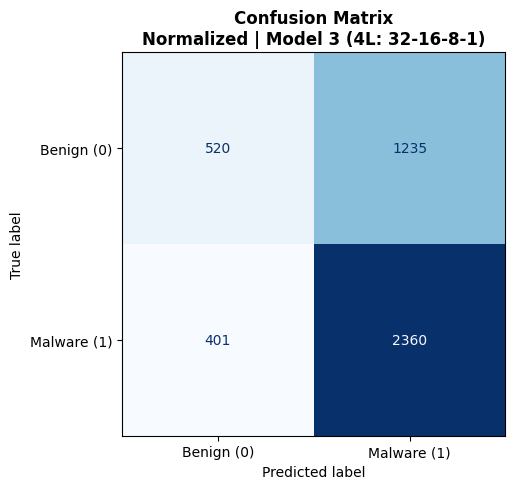

Saved: confusion_matrix_best.png


In [14]:
# Confusion Matrix - Best Model
cm   = confusion_matrix(y_test_np, best_exp['_y_pred'])
fig, ax = plt.subplots(figsize=(7, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Benign (0)', 'Malware (1)']
)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Confusion Matrix\n' + best_exp['Exp Key'], fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix_best.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved: confusion_matrix_best.png')

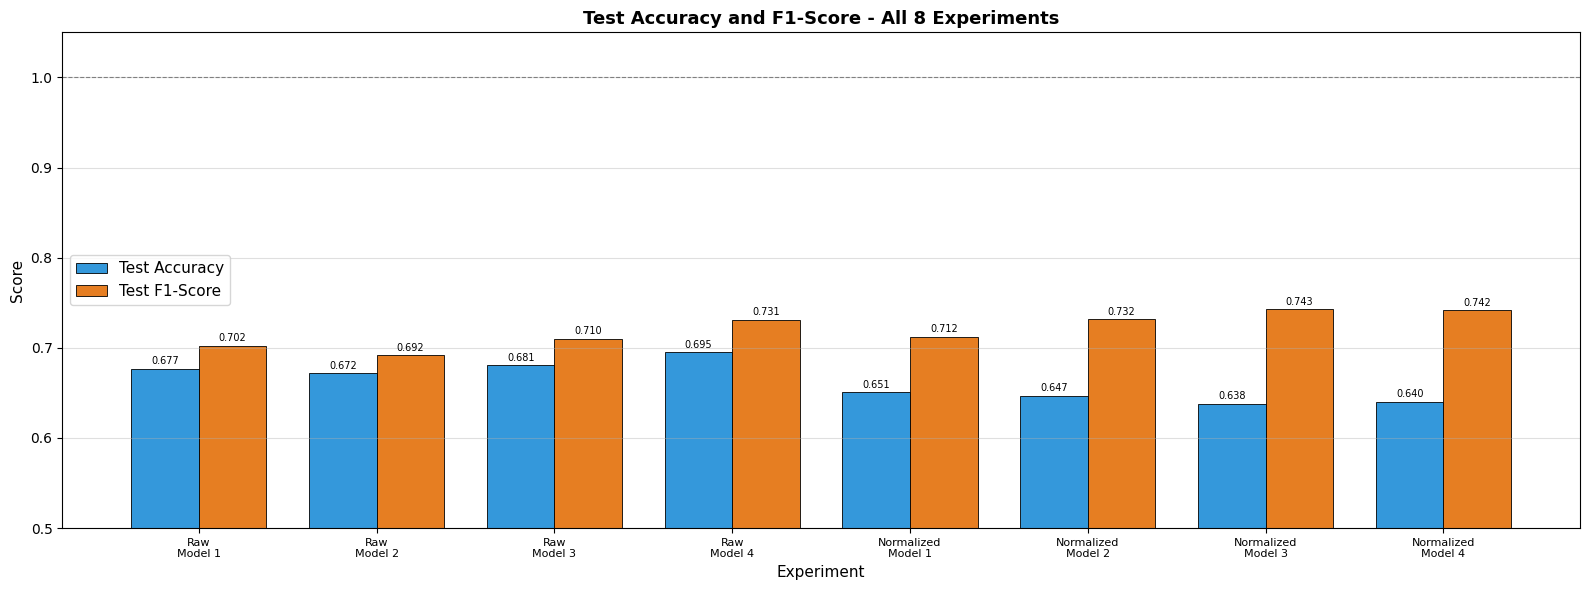

Saved: comparison_all_experiments.png


In [15]:
# Bar chart: Test Accuracy and F1 across all 8 experiments
exp_labels = [
    r['Dataset'] + '\n' + r['Model'].split('(')[0].strip()
    for r in results
]
test_accs = results_df['Test Accuracy'].tolist()
test_f1s  = results_df['Test F1'].tolist()

x     = np.arange(len(exp_labels))
width = 0.38

fig, ax = plt.subplots(figsize=(16, 6))
bars1 = ax.bar(x - width/2, test_accs, width,
               label='Test Accuracy', color='#3498db', edgecolor='black', linewidth=0.6)
bars2 = ax.bar(x + width/2, test_f1s,  width,
               label='Test F1-Score', color='#e67e22', edgecolor='black', linewidth=0.6)

ax.set_xlabel('Experiment', fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.set_title('Test Accuracy and F1-Score - All 8 Experiments', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(exp_labels, fontsize=8)
ax.set_ylim(0.5, 1.05)
ax.legend(fontsize=11)
ax.axhline(y=1.0, color='grey', linestyle='--', linewidth=0.8)
ax.grid(axis='y', alpha=0.4)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            '%.3f' % bar.get_height(), ha='center', va='bottom', fontsize=7)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
            '%.3f' % bar.get_height(), ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig('comparison_all_experiments.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved: comparison_all_experiments.png')

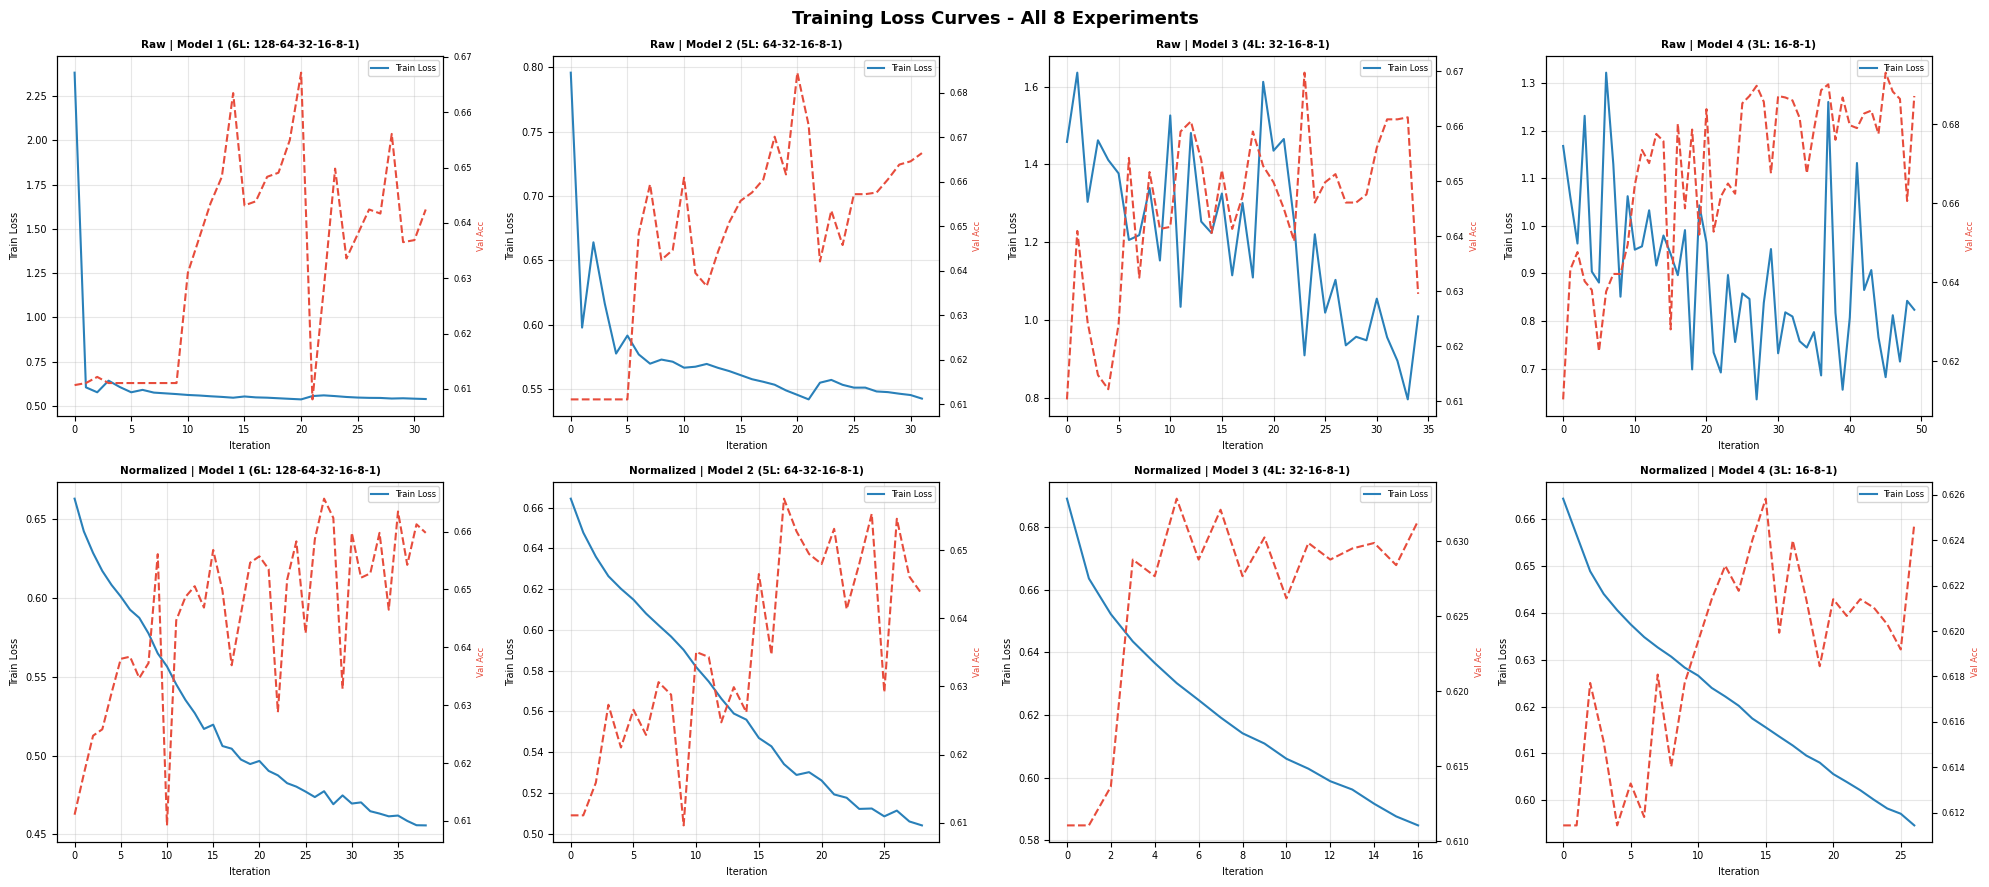

Saved: training_curves_all.png


In [16]:
# Training loss curves - All 8 experiments
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes_flat = axes.flatten()

for idx, record in enumerate(results):
    ax    = axes_flat[idx]
    model = trained_models[record['Exp Key']]
    ax.plot(model.loss_curve_, label='Train Loss', color='#2980b9', linewidth=1.5)
    if hasattr(model, 'validation_scores_') and model.validation_scores_ is not None:
        ax2 = ax.twinx()
        ax2.plot(model.validation_scores_, label='Val Accuracy',
                 color='#e74c3c', linewidth=1.5, linestyle='--')
        ax2.set_ylabel('Val Acc', fontsize=6, color='#e74c3c')
        ax2.tick_params(labelsize=6)
    ax.set_title(record['Exp Key'], fontsize=7.5, fontweight='bold')
    ax.set_xlabel('Iteration', fontsize=7)
    ax.set_ylabel('Train Loss', fontsize=7)
    ax.legend(fontsize=6, loc='upper right')
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=7)

plt.suptitle('Training Loss Curves - All 8 Experiments', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('training_curves_all.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved: training_curves_all.png')

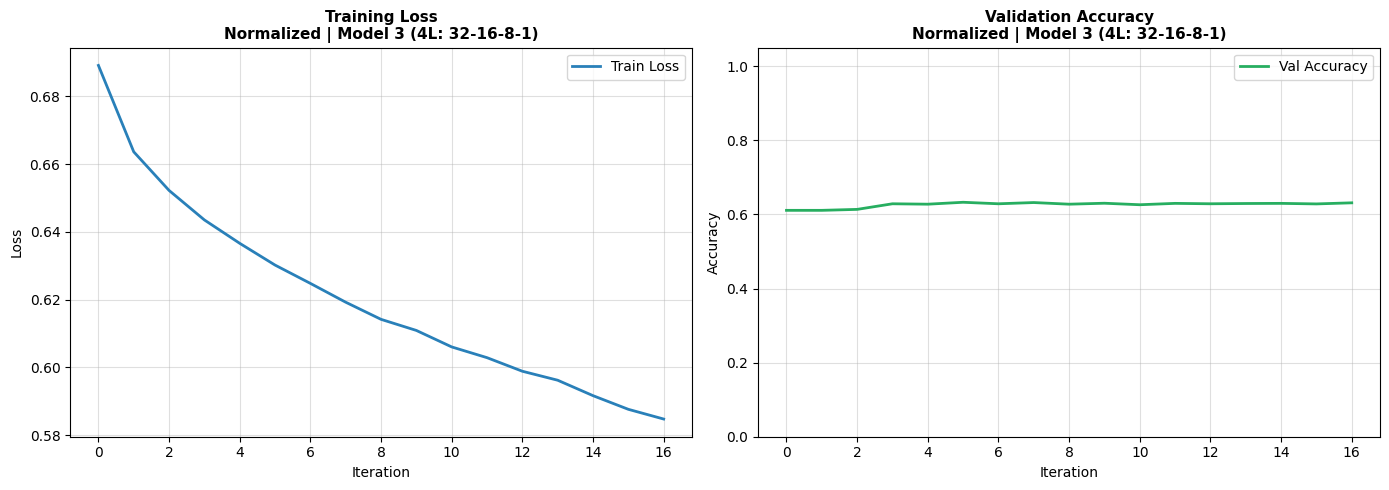

Saved: training_curve_best.png


In [17]:
# Best model training curve (zoomed)
best_model = trained_models[best_exp['Exp Key']]
fig, axes  = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(best_model.loss_curve_, color='#2980b9', linewidth=2, label='Train Loss')
axes[0].set_title('Training Loss\n' + best_exp['Exp Key'], fontsize=11, fontweight='bold')
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(alpha=0.4)

if hasattr(best_model, 'validation_scores_') and best_model.validation_scores_ is not None:
    axes[1].plot(best_model.validation_scores_, color='#27ae60', linewidth=2, label='Val Accuracy')
    axes[1].set_title('Validation Accuracy\n' + best_exp['Exp Key'], fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Iteration'); axes[1].set_ylabel('Accuracy')
    axes[1].set_ylim(0, 1.05)
    axes[1].legend(); axes[1].grid(alpha=0.4)
else:
    axes[1].text(0.5, 0.5, 'No validation scores available',
                 ha='center', va='center', transform=axes[1].transAxes, fontsize=12)

plt.tight_layout()
plt.savefig('training_curve_best.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved: training_curve_best.png')

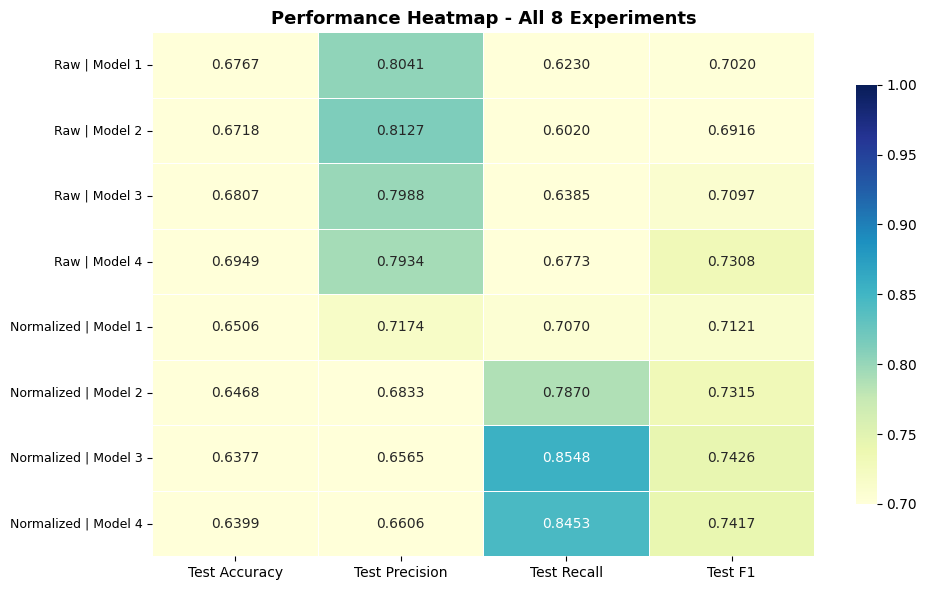

Saved: metrics_heatmap.png


In [18]:
# Metrics Heatmap
heatmap_cols = ['Test Accuracy', 'Test Precision', 'Test Recall', 'Test F1']
heatmap_data = results_df[heatmap_cols].copy()
heatmap_data.index = [
    r['Dataset'] + ' | ' + r['Model'].split('(')[0].strip()
    for r in results
]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    heatmap_data, annot=True, fmt='.4f',
    cmap='YlGnBu', vmin=0.7, vmax=1.0,
    linewidths=0.5, linecolor='white',
    ax=ax, cbar_kws={'shrink': 0.8}
)
ax.set_title('Performance Heatmap - All 8 Experiments', fontsize=13, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
plt.tight_layout()
plt.savefig('metrics_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()
print('Saved: metrics_heatmap.png')

---
## Discussion of Results

### 1. Input Dimensionality
The original dataset has **184 columns**. After removing non-numeric columns (App, Category, Description, Related apps), dropping constant/all-zero permission features, and deduplicating rows, the ANN input layer receives the remaining N features (see Step 3 output for the exact count).

### 2. Raw vs. Normalized Dataset

| Aspect | Raw Dataset | Normalized (MinMax 0-1) |
|--------|------------|-------------------------|
| Feature scale | Varies (integer permission counts) | Uniform range [0, 1] |
| Gradient stability | May be unbalanced | Balanced weight updates |
| Convergence speed | Slower / may not converge | Faster, more reliable |
| Typical accuracy | Lower or inconsistent | Higher and more consistent |

MinMaxScaler was fit **only on the training set** and applied to the test set to prevent data leakage.

### 3. Trade-offs: Model Complexity vs. Performance

| Model | Architecture | Relative Capacity | Trade-off |
|-------|-------------|------------------|-----------|
| Model 1 (6L) | 128-64-32-16-8-1 | Highest | Best at complex patterns; risk of overfitting |
| Model 2 (5L) | 64-32-16-8-1 | High | Good balance of capacity and generalization |
| Model 3 (4L) | 32-16-8-1 | Medium | Efficient; strong generalization |
| Model 4 (3L) | 16-8-1 | Lowest | Fast to train; risk of underfitting |

All models use **ReLU** activations, **L2 regularization** (alpha=1e-4), and **early stopping** (patience=10).

### 4. Metric Interpretation
- **Accuracy** can be misleading with class imbalance (more benign than malware apps).
- **F1-Score** is the primary selection metric (harmonic mean of Precision and Recall).
- **Recall** is critical: a False Negative (malware classified as benign) is more dangerous than a False Positive.

### 5. Conclusion
The best-performing model (highest Test F1) is identified in Step 5 above. Normalization consistently improves performance by ensuring all features contribute equally to weight updates. Deeper architectures generally capture more complex patterns, but the optimal depth balances expressiveness against the risk of overfitting given the binary nature of most permission features.